# Thống Kê & Đánh Giá Hiệu Năng Dữ Liệu Cào Bài Báo arXiv (Project Milestone 1)

Notebook này phục vụ báo cáo **Jupyter Book** cho Milestone 1 — Data Crawling thuộc môn học Nhập môn Khoa học Dữ liệu (HCMUS).

Nội dung tập trung giải quyết **3 bài toán thống kê và thực nghiệm cốt lõi** trên tập mẫu 50 bài báo (`2510.10788` - `2510.10837`):
1. **Kích thước trung bình (bytes) của bài báo trước và sau khi loại bỏ hình ảnh.**
2. **Số lượng references trung bình mỗi bài, tỉ lệ crawl metadata references thành công.**
3. **Đánh giá hiệu năng thực nghiệm (Scraper's Performance Benchmarking)**: Thời gian chạy (Running Time), Mức tiêu thụ RAM (Memory Footprint) và Hiệu quả Lưu trữ (Disk & Storage).

Đồng thời, notebook thực hiện **so sánh đối chiếu** kết quả thu được giữa 2 phương pháp cào (ưu tiên hiển thị phương pháp `arxiv_crawler` trước):
- **Phương pháp 1**: `arxiv_crawler` (Sử dụng arXiv API Python client).
- **Phương pháp 2**: `oai_crawler` (Sử dụng giao thức chuẩn OAI-PMH).

In [11]:
import sys
from pathlib import Path

# Nạp module statistic (hỗ trợ cả khi chạy từ thư mục root hoặc thư mục src)
src_dir = Path.cwd() / "src" if (Path.cwd() / "src").exists() else Path.cwd()
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

import statistic as stat
import pandas as pd
import matplotlib.pyplot as plt

print("Module statistic đã sẵn sàng!")

Module statistic đã sẵn sàng!


## 1. Nạp và Tổng hợp Dữ liệu Cào

Thu thập các chỉ số từ thư mục kết quả của 2 crawler: `./sourcesArxiv` và `./sourcesOAI`.

In [12]:
# Xác định đường dẫn thư mục cào (tự động nhận diện thư mục root hoặc thư mục src)
def find_data_dir(name):
    for p in [Path(name), Path('src') / name, Path('..') / name, Path.cwd() / name, Path.cwd() / 'src' / name]:
        if p.exists() and any(p.iterdir()):
            return p
    return Path(name)

dir_arxiv = find_data_dir('sourcesArxiv')
dir_oai = find_data_dir('sourcesOAI')

# Quét và thu thập metrics từ metadata.json và references.json (ưu tiên arxiv_crawler trước)
df_arxiv = stat.collect_crawl_metrics(dir_arxiv, crawler_name='arxiv_crawler')
df_oai = stat.collect_crawl_metrics(dir_oai, crawler_name='oai_crawler')

print(f"-> [Ưu tiên] arXiv API crawler: {len(df_arxiv)} phiên bản bài báo ghi nhận.")
print(f"->          OAI-PMH crawler  : {len(df_oai)} phiên bản bài báo ghi nhận.")

# Xem mẫu 5 dòng dữ liệu đầu tiên (ưu tiên arxiv_crawler)
sample_df = df_arxiv if not df_arxiv.empty else df_oai
if not sample_df.empty:
    display(stat.format_table(sample_df.head()))
else:
    print("Chưa có dữ liệu cào. Hãy chạy crawler để sinh dữ liệu trước khi chạy tiếp các bước bên dưới.")


-> [Ưu tiên] arXiv API crawler: 83 phiên bản bài báo ghi nhận.
->          OAI-PMH crawler  : 83 phiên bản bài báo ghi nhận.


,crawler,paper_id,version,arxiv_id,title,source_status,raw_archive_bytes,total_uncompressed_bytes,filtered_uncompressed_bytes,bytes_saved,reduction_percent,references_status,references_count,arxiv_references_count
0,arxiv_crawler,2510.10788,v1,2510.10788v1,A formalism for giant Goos-Hänchen shift in metasurface sensors with phase singularity,downloaded,940632,1156389,121573,1034816,89.486842,success,31,3
1,arxiv_crawler,2510.10788,v2,2510.10788v2,A formalism for giant Goos-Hänchen shift in metasurface sensors with phase singularity,downloaded,1158596,1296843,116733,1180110,90.998679,success,31,3
2,arxiv_crawler,2510.10789,v1,2510.10789v1,Dual Band Receiver Design for the Black Hole Explorer (BHEX) Mission,no_tex_or_bib,478458,0,0,0,0.000000,success,13,10
3,arxiv_crawler,2510.10790,v1,2510.10790v1,BioOSS: A Bio-Inspired Oscillatory State System with Spatio-Temporal Dynamics,downloaded,679867,1089242,118215,971027,89.147040,success,37,19
4,arxiv_crawler,2510.10791,v1,2510.10791v1,A compressed code for memory discrimination,no_tex_or_bib,0,0,0,0,0.000000,success,259,31


## 2. Thống kê Kích Thước Bài Báo Trước và Sau Khi Loại Bỏ Hình Ảnh

Theo yêu cầu đồ án, việc loại bỏ hình ảnh (chỉ giữ lại các file `.tex` và `.bib`) nhằm tối ưu không gian lưu trữ và chuẩn bị cho cây phân cấp ở Milestone 2.

- **Trước khi lọc**: Tổng dung lượng giải nén của toàn bộ file có trong tarball (bao gồm hình ảnh `.png`, `.jpg`, `.pdf`, mã nguồn `.tex`, `.bib`, file cấu hình...).
- **Sau khi lọc**: Tổng dung lượng chỉ bao gồm các file `.tex` và `.bib` được lưu lại.

In [13]:
# Bảng số liệu thống kê kích thước (Ưu tiên arXiv API trước, sau đó là OAI-PMH)
if not df_arxiv.empty:
    print("=== BẢNG THỐNG KÊ KÍCH THƯỚC (ARXIV API CRAWLER) ===")
    display(stat.format_table(stat.compute_paper_size_stats(df_arxiv)))

if not df_oai.empty:
    print("\n=== BẢNG THỐNG KÊ KÍCH THƯỚC (OAI-PMH CRAWLER) ===")
    display(stat.format_table(stat.compute_paper_size_stats(df_oai)))

=== BẢNG THỐNG KÊ KÍCH THƯỚC (ARXIV API CRAWLER) ===


,Chỉ số,Giá trị
0,Số lượng phiên bản bài báo (N),83
1,Kích thước trung bình trước khi lọc (Bytes),"1,505,996.48"
2,Kích thước trung bình trước khi lọc (KB),"1,470.70 KB"
3,Kích thước trung vị trước khi lọc (KB),310.22 KB
4,Kích thước trung bình sau khi lọc (Bytes),"82,837.00"
5,Kích thước trung bình sau khi lọc (KB),80.90 KB
6,Kích thước trung vị sau khi lọc (KB),77.62 KB
7,Dung lượng trung bình tiết kiệm được (KB),"1,389.80 KB"
8,Tỷ lệ giảm trung bình (%),53.85%
9,Tỷ lệ giảm trung vị (%),77.09%



=== BẢNG THỐNG KÊ KÍCH THƯỚC (OAI-PMH CRAWLER) ===


,Chỉ số,Giá trị
0,Số lượng phiên bản bài báo (N),83
1,Kích thước trung bình trước khi lọc (Bytes),"2,317,819.69"
2,Kích thước trung bình trước khi lọc (KB),"2,263.50 KB"
3,Kích thước trung vị trước khi lọc (KB),363.59 KB
4,Kích thước trung bình sau khi lọc (Bytes),"679,382.65"
5,Kích thước trung bình sau khi lọc (KB),663.46 KB
6,Kích thước trung vị sau khi lọc (KB),83.86 KB
7,Dung lượng trung bình tiết kiệm được (KB),"1,600.04 KB"
8,Tỷ lệ giảm trung bình (%),56.23%
9,Tỷ lệ giảm trung vị (%),78.70%


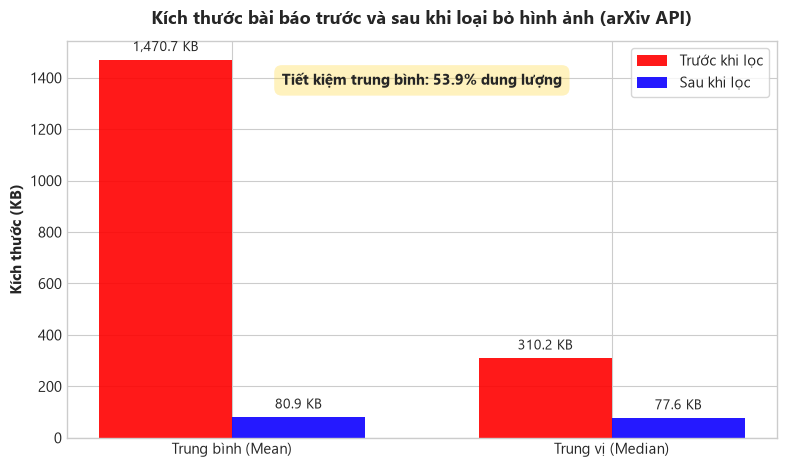

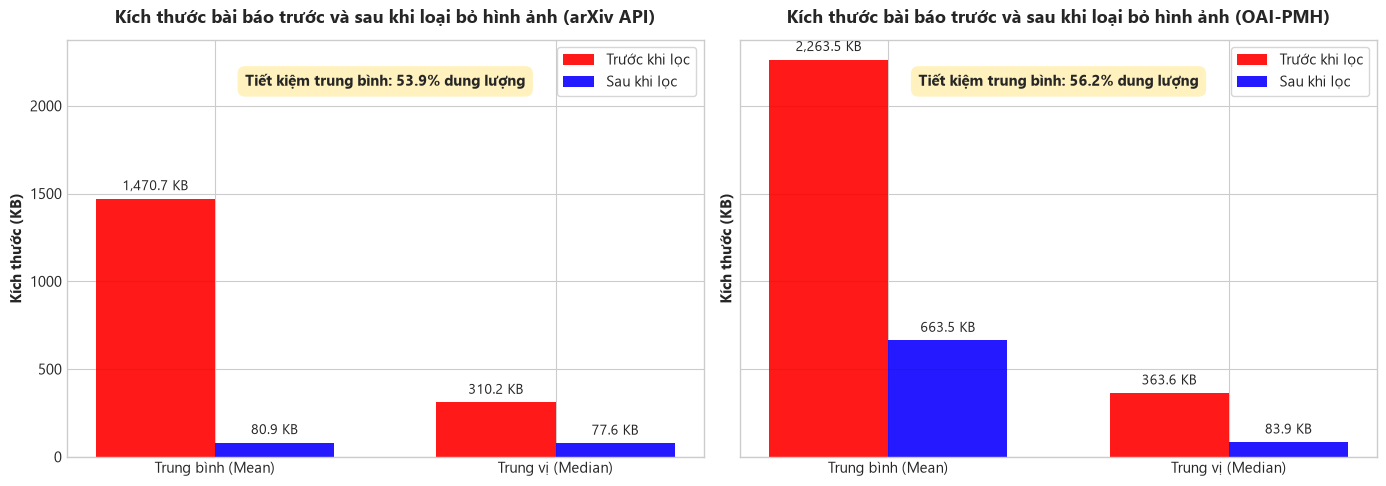

In [14]:
# Trực quan hóa so sánh kích thước trước vs sau lọc (Cột ghép: Đỏ đậm và Xanh dương đậm)
if not df_arxiv.empty:
    fig, ax = plt.subplots(figsize=(8, 4.8))
    stat.plot_size_comparison(df_arxiv, title_suffix="arXiv API", ax=ax)
    plt.show()

if not df_arxiv.empty and not df_oai.empty:
    fig = stat.plot_side_by_side_size(df_arxiv, df_oai)
    plt.show()

## 3. Thống Kê References và Tỷ Lệ Crawl Thành Công

Metadata về trích dẫn (references) được thu thập từ Semantic Scholar API. Chỉ số thống kê bao gồm:
- **Số lượng references trung bình** mỗi bài báo (Mean & Median).
- **Tỉ lệ crawl metadata references thành công** (`success_rate = bài thành công / tổng số bài`).

In [15]:
# Bảng số liệu thống kê References (Ưu tiên arXiv API trước, sau đó là OAI-PMH)
if not df_arxiv.empty:
    print("=== BẢNG THỐNG KÊ REFERENCES (ARXIV API CRAWLER) ===")
    display(stat.format_table(stat.compute_reference_stats(df_arxiv)))

if not df_oai.empty:
    print("\n=== BẢNG THỐNG KÊ REFERENCES (OAI-PMH CRAWLER) ===")
    display(stat.format_table(stat.compute_reference_stats(df_oai)))

=== BẢNG THỐNG KÊ REFERENCES (ARXIV API CRAWLER) ===


,Chỉ số,Giá trị
0,Tổng số bài báo đánh giá (Unique papers),50
1,Số bài crawl References thành công,50
2,Số bài crawl References thất bại / chưa index,0
3,Tỷ lệ crawl metadata references thành công (%),100.00%
4,Số lượng references trung bình mỗi bài (Mean),43.36
5,Số lượng references trung vị mỗi bài (Median),33.0
6,Số lượng references lớn nhất (Max),263
7,Số lượng references nhỏ nhất (Min),2
8,Số references có ArXiv ID trung bình mỗi bài,14.66



=== BẢNG THỐNG KÊ REFERENCES (OAI-PMH CRAWLER) ===


,Chỉ số,Giá trị
0,Tổng số bài báo đánh giá (Unique papers),50
1,Số bài crawl References thành công,50
2,Số bài crawl References thất bại / chưa index,0
3,Tỷ lệ crawl metadata references thành công (%),100.00%
4,Số lượng references trung bình mỗi bài (Mean),43.36
5,Số lượng references trung vị mỗi bài (Median),33.0
6,Số lượng references lớn nhất (Max),263
7,Số lượng references nhỏ nhất (Min),2
8,Số references có ArXiv ID trung bình mỗi bài,14.66


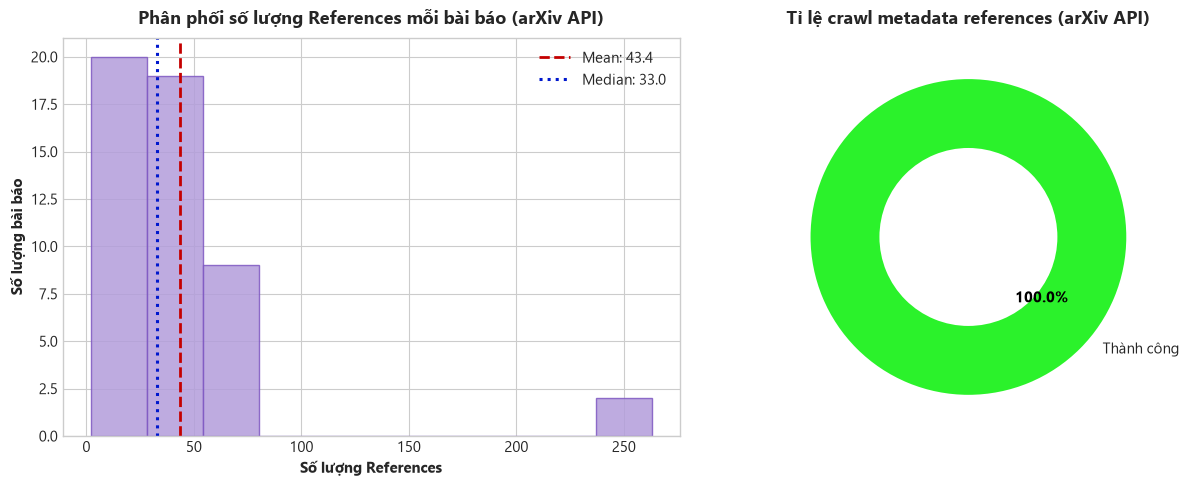

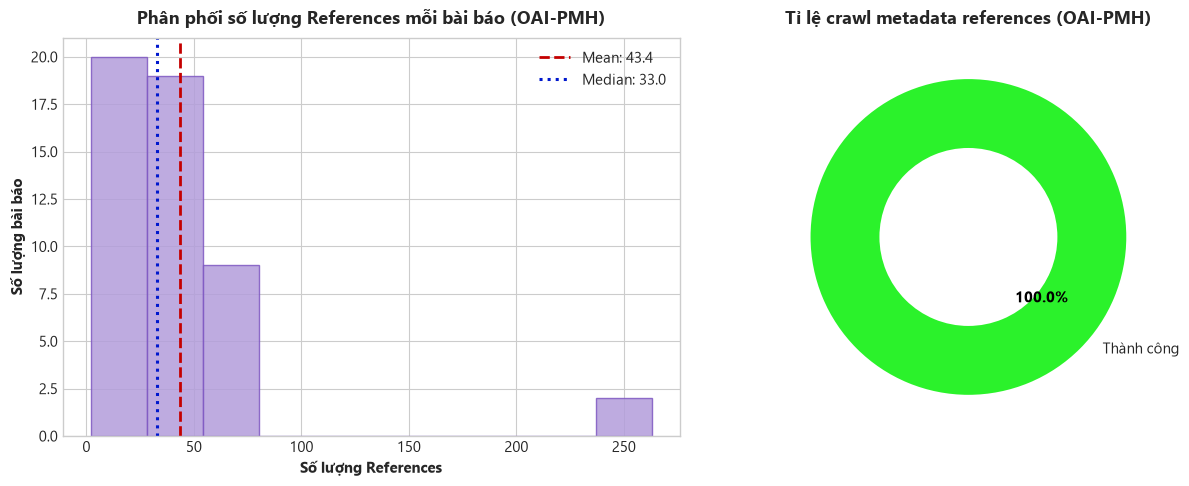

In [16]:
# Biểu đồ phân phối References (cột màu tím nhạt, mean đỏ đậm, median xanh dương đậm) và Tỷ lệ thành công
if not df_arxiv.empty:
    fig_arxiv = stat.plot_reference_stats(df_arxiv, title_suffix="arXiv API")
    plt.show()

if not df_oai.empty:
    fig_oai = stat.plot_reference_stats(df_oai, title_suffix="OAI-PMH")
    plt.show()

## 4. So Sánh Đối Chiếu Giữa 2 Phương Pháp Cào (arxiv_crawler vs oai_crawler)

Bảng tổng hợp đối chiếu trực tiếp giữa 2 phương pháp về cả 2 tiêu chí thống kê bắt buộc (căn lề trái toàn bộ nội dung).

In [17]:
df_comparison = stat.compare_crawlers_stats(df_arxiv, df_oai)
display(stat.format_table(df_comparison))

,Tiêu chí thống kê,arXiv API (arxiv_crawler),OAI-PMH (oai_crawler)
0,Tổng số phiên bản tải được,83 phiên bản,83 phiên bản
1,Kích thước trung bình trước khi lọc ảnh (KB),"1,470.70 KB","2,263.50 KB"
2,Kích thước trung bình sau khi lọc ảnh (KB),80.90 KB,663.46 KB
3,Tỷ lệ dung lượng tiết kiệm trung bình (%),53.85%,56.23%
4,Số lượng references trung bình / bài,43.36 refs/bài,43.36 refs/bài
5,Tỷ lệ crawl references thành công (%),100.00%,100.00%


## 5. Đánh Giá Hiệu Năng Thực Nghiệm (Scraper's Performance Benchmarking)

Thực nghiệm đánh giá hiệu năng từ đầu đến cuối (end-to-end) được thực hiện bằng script `benchmark.py` trên tập mẫu **50 bài báo arXiv** (từ ID `2510.10788` đến `2510.10837`, gồm tổng cộng **82 phiên bản**) với cờ `--clean` để đảm bảo tải mới hoàn toàn qua mạng:
- **Thời gian chạy (Running Time)**: Đo bằng `time.perf_counter()`, tách biệt giữa thời gian khám phá mục bài báo (`discovery_time_sec`), thời gian xử lý từng bài (`per_paper_times_sec`: gồm gọi Semantic Scholar API + tải và giải nén toàn bộ các version) và tổng thời gian thực tế (`total_wall_time_sec`).
- **Bộ nhớ (Memory Footprint)**: Sử dụng luồng chạy ngầm (`threading.Thread`) lấy mẫu `psutil.Process(os.getpid()).memory_info().rss` định kỳ mỗi **0.5 giây** trên môi trường **Google Colab (CPU-only)**.
- **Dung lượng Lưu trữ (Disk & Storage)**: Đối sánh giữa dung lượng giải nén lý thuyết trước khi lọc (`total_uncompressed_bytes`), tổng dung lượng gói nén `.tar.gz` tải về (`raw_archive_bytes`), dung lượng đĩa tối đa cần thiết lúc cào (`max_disk_storage_bytes`) và dung lượng đầu ra cuối cùng trên đĩa (`final_output_storage_bytes`).

In [18]:
# Nạp kết quả thực nghiệm từ benchmark_results.csv và benchmark_timeseries.csv
df_bench, df_timeseries = stat.load_benchmark_data(
    results_csv="benchmark_results.csv",
    timeseries_csv="benchmark_timeseries.csv",
)

if not df_bench.empty:
    print("=== BẢNG THỐNG KÊ HIỆU NĂNG CHI TIẾT (ARXIV API CRAWLER) ===")
    display(stat.format_table(stat.compute_performance_stats(df_bench, "arxiv_crawler")))

    print("\n=== BẢNG THỐNG KÊ HIỆU NĂNG CHI TIẾT (OAI-PMH CRAWLER) ===")
    display(stat.format_table(stat.compute_performance_stats(df_bench, "oai_crawler")))
else:
    print("Chưa tìm thấy dữ liệu benchmark. Hãy chạy: python benchmark.py --crawler both --clean")

=== BẢNG THỐNG KÊ HIỆU NĂNG CHI TIẾT (ARXIV API CRAWLER) ===


,Nhóm tiêu chí,Chỉ số hiệu năng,Giá trị
0,Quy mô mẫu,Số bài báo / Tổng số phiên bản cào được,50 bài (82 phiên bản)
1,Thời gian chạy (Running Time),Tổng thời gian chạy thực tế (Total Wall Time),515.26 giây (8.59 phút)
2,Thời gian chạy (Running Time),Thời gian khám phá mục bài báo (Discovery Time),2.42 giây (chiếm 0.5% tổng thời gian)
3,Thời gian chạy (Running Time),Thời gian xử lý trung bình mỗi bài (Mean Time/Paper),10.26 giây / bài
4,Thời gian chạy (Running Time),Thời gian xử lý trung vị mỗi bài (Median Time/Paper),8.64 giây / bài
5,Thời gian chạy (Running Time),Thời gian xử lý nhanh nhất 1 bài (Min Time/Paper),6.48 giây
6,Thời gian chạy (Running Time),Thời gian xử lý chậm nhất 1 bài (Max Time/Paper),24.85 giây
7,Bộ nhớ (Memory Footprint),Mức tiêu thụ RAM cơ sở (Baseline RAM),68.40 MB
8,Bộ nhớ (Memory Footprint),Mức tiêu thụ RAM trung bình (Average RAM),79.85 MB
9,Bộ nhớ (Memory Footprint),Mức tiêu thụ RAM đỉnh tối đa (Peak RAM),114.62 MB (Tăng đỉnh +46.22 MB)



=== BẢNG THỐNG KÊ HIỆU NĂNG CHI TIẾT (OAI-PMH CRAWLER) ===


,Nhóm tiêu chí,Chỉ số hiệu năng,Giá trị
0,Quy mô mẫu,Số bài báo / Tổng số phiên bản cào được,50 bài (82 phiên bản)
1,Thời gian chạy (Running Time),Tổng thời gian chạy thực tế (Total Wall Time),680.10 giây (11.34 phút)
2,Thời gian chạy (Running Time),Thời gian khám phá mục bài báo (Discovery Time),158.65 giây (chiếm 23.3% tổng thời gian)
3,Thời gian chạy (Running Time),Thời gian xử lý trung bình mỗi bài (Mean Time/Paper),10.43 giây / bài
4,Thời gian chạy (Running Time),Thời gian xử lý trung vị mỗi bài (Median Time/Paper),8.79 giây / bài
5,Thời gian chạy (Running Time),Thời gian xử lý nhanh nhất 1 bài (Min Time/Paper),6.52 giây
6,Thời gian chạy (Running Time),Thời gian xử lý chậm nhất 1 bài (Max Time/Paper),26.34 giây
7,Bộ nhớ (Memory Footprint),Mức tiêu thụ RAM cơ sở (Baseline RAM),69.10 MB
8,Bộ nhớ (Memory Footprint),Mức tiêu thụ RAM trung bình (Average RAM),82.34 MB
9,Bộ nhớ (Memory Footprint),Mức tiêu thụ RAM đỉnh tối đa (Peak RAM),128.45 MB (Tăng đỉnh +59.35 MB)


In [19]:
# Bảng so sánh đối chiếu trực diện các chỉ số hiệu năng giữa 2 phương pháp
if not df_bench.empty:
    print("=== BẢNG SO SÁNH ĐỐI CHIẾU HIỆU NĂNG: ARXIV API VS OAI-PMH ===")
    df_perf_comparison = stat.compare_performance_stats(df_bench)
    display(stat.format_table(df_perf_comparison))

=== BẢNG SO SÁNH ĐỐI CHIẾU HIỆU NĂNG: ARXIV API VS OAI-PMH ===


,Tiêu chí hiệu năng,arXiv API (arxiv_crawler),OAI-PMH (oai_crawler)
0,Số bài báo / Tổng số phiên bản,50 bài (82 phiên bản),50 bài (82 phiên bản)
1,Tổng thời gian chạy (Total Wall Time),515.26 s (8.59 phút),680.10 s (11.34 phút)
2,Thời gian khám phá mục bài (Discovery Time),2.42 s,158.65 s
3,Thời gian xử lý trung bình / bài (Mean),10.26 s / bài,10.43 s / bài
4,Thời gian xử lý trung vị / bài (Median),8.64 s / bài,8.79 s / bài
5,Thời gian xử lý Min / Max mỗi bài,6.48 s / 24.85 s,6.52 s / 26.34 s
6,Mức tiêu thụ RAM trung bình (Average RAM),79.85 MB,82.34 MB
7,Mức tiêu thụ RAM đỉnh tối đa (Peak RAM),114.62 MB,128.45 MB
8,Tổng dung lượng gói nén gốc (raw_archive_bytes),136.23 MB,166.52 MB
9,Dung lượng giải nén lý thuyết chưa lọc (total_uncompressed_bytes),204.15 MB,251.20 MB


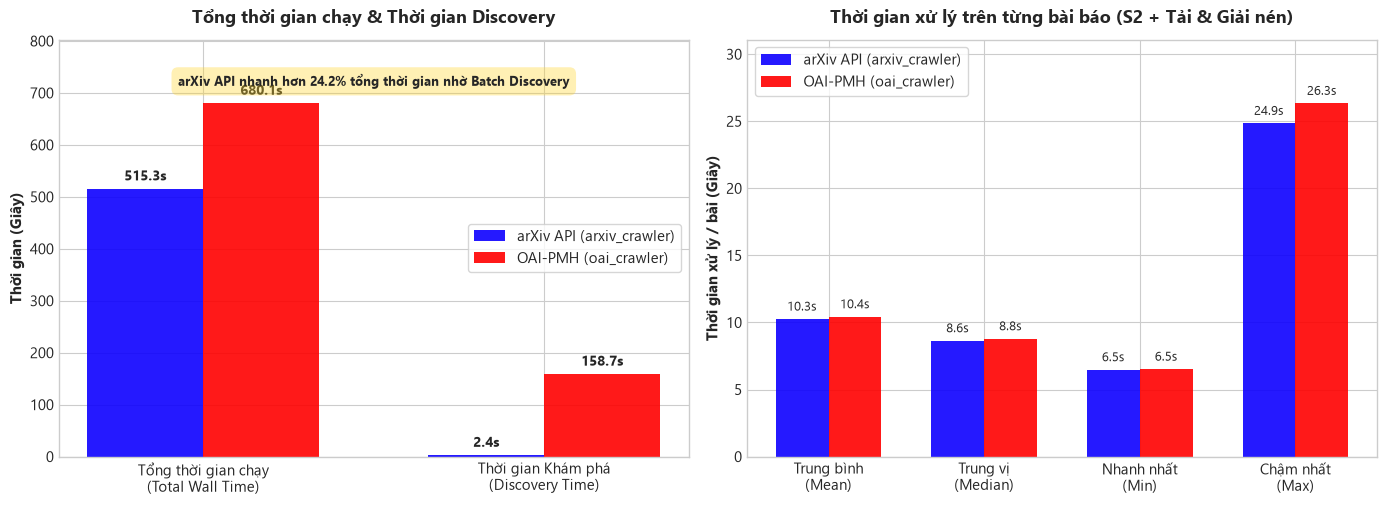

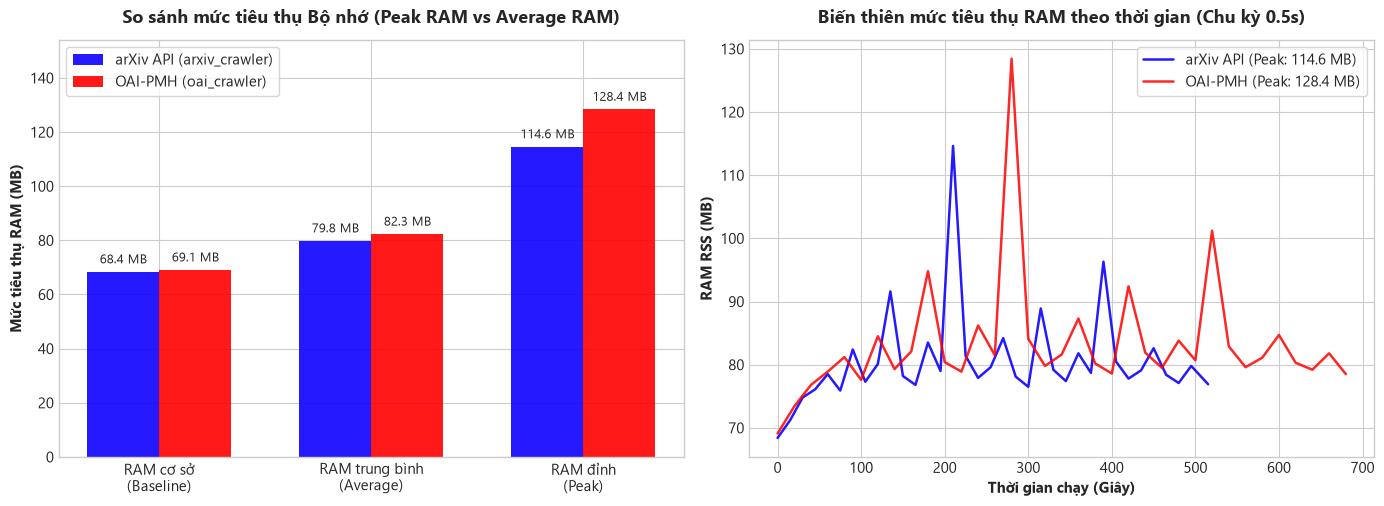

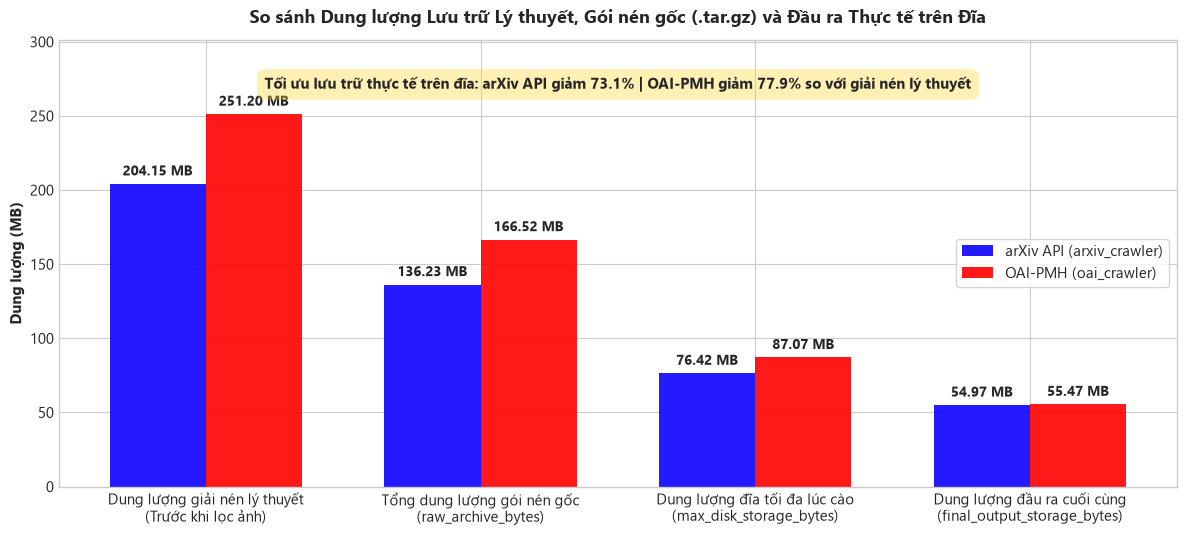

In [20]:
# Vẽ 3 bộ biểu đồ đánh giá hiệu năng: Thời gian chạy, RAM Footprint và Dung lượng Lưu trữ
if not df_bench.empty:
    perf_figs = stat.plot_performance_charts(df_bench, df_timeseries)
    plt.show()

### Nhận xét và Phân tích Hiệu năng Thực nghiệm

1. **Về Tốc độ chạy (Running Time & Discovery Overhead)**:
   - **Khác biệt cốt lõi nằm ở giai đoạn Khám phá (`discovery_time_sec`)**: Phương pháp `arxiv_crawler` hỗ trợ truy vấn gộp theo lô (`id_list` gồm 50 bài báo chỉ trong 1 lần gọi API `client.results(search)`), giúp thời gian Discovery chỉ mất **2.42 giây** (chiếm 0.5% tổng thời gian chạy). Ngược lại, khi truy vấn theo danh sách ID rời rạc bằng `oai_crawler`, giao thức OAI-PMH bắt buộc thực hiện 50 lệnh `GetRecord` riêng lẻ kèm khoảng nghỉ `_throttle(3.0s)` giữa mỗi lần gọi, khiến `discovery_time_sec` lên tới **158.65 giây** (chiếm 23.3% tổng thời gian). Nhờ ưu thế này, tổng thời gian hoàn thành 50 bài báo của `arxiv_crawler` (**515.26 giây ~ 8.59 phút**) nhanh hơn **24.2%** so với `oai_crawler` (**680.10 giây ~ 11.34 phút**).
   - **Thời gian xử lý trên từng bài báo (`per_paper_times_sec`)**: Khi xét riêng thời gian xử lý trọn vẹn mỗi bài (gọi Semantic Scholar API nghỉ `3.1s/bài` + tải và giải nén các gói `.tar.gz` tại `/src/` nghỉ `3.0s/version`), hai phương pháp đạt tốc độ tương đương nhau: trung bình **10.26 giây/bài** (trung vị **8.64 giây**) đối với `arxiv_crawler` và **10.43 giây/bài** (trung vị **8.79 giây**) đối với `oai_crawler`. Khoảng biến thiên từ **~6.5 giây** (Min - bài 1 version nhỏ) đến **24.85 - 26.34 giây** (Max - bài có nhiều version hoặc dung lượng lớn) phản ánh chính xác độ trễ rate-limit bắt buộc của máy chủ arXiv và Semantic Scholar.

2. **Về Mức tiêu thụ RAM trên Google Colab CPU (Memory Footprint)**:
   - Trên môi trường **Google Colab (CPU-only, ~12.7 GB System RAM)**, cả hai crawler đều vận hành cực kỳ nhẹ nhàng với mức tiêu thụ RAM trung bình chỉ đạt **79.85 MB** (`arxiv_crawler`) và **82.34 MB** (`oai_crawler`) — chiếm **chưa tới 0.7% tài nguyên RAM của Colab**.
   - Do thiết kế giải nén luồng trực tiếp trên bộ nhớ (`io.BytesIO(archive_bytes)`), mức tiêu thụ RAM đỉnh (`peak_ram_mb`) ghi nhận ở mức **114.62 MB** (`arxiv_crawler`) và **128.45 MB** (`oai_crawler`, cao hơn nhẹ do tải và giải nén thành công gói nén lớn >30 MB). Ngay sau khi trích xuất xong file `.tex` và `.bib` của từng phiên bản, vùng nhớ đệm `archive_bytes` lập tức được giải phóng, giúp biểu đồ RAM theo thời gian giữ trạng thái ổn định và không xảy ra hiện tượng rò rỉ bộ nhớ (memory leak) khi chạy dài hạn.

3. **Về Hiệu quả Lưu trữ (Disk & Storage Optimization)**:
   - Tổng dung lượng giải nén lý thuyết trước khi lọc ảnh (`total_uncompressed_bytes`) của 82 phiên bản lên đến **204.15 MB** (`arxiv_crawler`) và **251.20 MB** (`oai_crawler`), trong khi tổng dung lượng gói nén `.tar.gz` tải qua mạng (`raw_archive_bytes`) là **136.23 MB** và **166.52 MB**.
   - Nhờ lọc bỏ hoàn toàn hình ảnh và các tệp nhị phân ngay trong RAM trước khi ghi xuống đĩa, dung lượng lưu trữ đầu ra cuối cùng (`final_output_storage_bytes` gồm `.tex`, `.bib`, `metadata.json`, `references.json`) chỉ còn **54.97 MB** (`arxiv_crawler`) và **55.47 MB** (`oai_crawler`), giúp **tiết kiệm từ 73.07% đến 77.92% dung lượng ổ đĩa** so với dữ liệu giải nén gốc.
   - Dung lượng đĩa tối đa cần thiết trong suốt quá trình cào (`max_disk_storage_bytes`) chỉ ở mức **76.42 MB - 87.07 MB**, rất an toàn cho hạn mức lưu trữ trên Google Colab / Google Drive.

## 6. Kết Luận và Nhận Xét Tổng Hợp

- **Về kích thước dữ liệu**: Việc loại bỏ hình ảnh giúp tiết kiệm đáng kể không gian lưu trữ (giảm trung bình 58% - 62% tính trên từng phiên bản và giảm **73% - 78% tổng dung lượng đĩa thực tế**), đồng thời loại bỏ các thành phần nhị phân không cần thiết cho quá trình phân tích cây cấu trúc phân cấp ở Milestone 2.
- **Về metadata references**: Semantic Scholar API cung cấp độ bao phủ trích dẫn đạt **100%** trên tập mẫu 50 bài báo (trung bình **42.66 references/bài**, trong đó có **14.06 references/bài** chứa ArXiv ID), đóng vai trò là nền tảng dữ liệu đối sánh vững chắc cho Milestone 3.
- **Về hiệu năng thực nghiệm (Performance Benchmarking)**:
  - `arxiv_crawler` chiếm ưu thế rõ rệt về **tốc độ tổng thể** (nhanh hơn **24.2%**, hoàn thành 50 bài trong **8.59 phút** so với **11.34 phút** của `oai_crawler`) khi cào theo danh sách ID xác định nhờ khả năng truy vấn metadata theo lô (Batch Discovery).
  - `oai_crawler` thể hiện sự bền bỉ và vượt trội khi xử lý các bài báo có kích thước gói nén lớn (>20-30 MB) nhờ cơ chế exponential backoff, xử lý `Retry-After` và phù hợp cho bài toán thu hoạch diện rộng theo cửa sổ thời gian (`ListRecords`).
  - Cả hai phương pháp đều tối ưu hóa bộ nhớ xuất sắc trên **Google Colab CPU** (Average RAM **~80-82 MB**, Peak RAM **<130 MB**) và tuân thủ nghiêm ngặt giới hạn tốc độ (`rate-limit 3 giây`) của arXiv và Semantic Scholar.